# 02 — On/Off-policy Monte Carlo Prediction

완료 Episode의 Return으로 고정 정책 Vπ를 추정한다. First-visit는 시간상 첫 방문,
Every-visit는 모든 방문이다. Off-policy에서는 수집 시 log b를 보존하고 Ordinary IS와 Weighted IS를 비교한다.
Target π와 Behavior b를 구분하며 Coverage는 수집자가 보장한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl import Model
from modular_rl import representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.data import Transition, Episode
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
N_STATES, N_ACTIONS = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
behavior = Model(R.Identity(), E.TabularQ(N_STATES,N_ACTIONS), S.EpsilonGreedy(1.)).double()
return_generator = T.MCReturn(GAMMA)
models = {name: Model(R.Identity(), E.TabularV(N_STATES)).double()
          for name in ('first','every','ordinary','weighted')}
target_policy = torch.tensor([[.3,.2,.2,.3]]*N_STATES, dtype=torch.float64)
learners = {
    'first': L.MCPrediction(models['first'], return_generator, visit_mode='first'),
    'every': L.MCPrediction(models['every'], return_generator, visit_mode='every'),
    'ordinary': L.OffPolicyMCPrediction(models['ordinary'], return_generator, target_policy, method='ordinary'),
    'weighted': L.OffPolicyMCPrediction(models['weighted'], return_generator, target_policy, method='weighted'),
}
mdp = frozenlake_mdp(env)
reference = policy_evaluation(mdp, uniform_policy(mdp), gamma=GAMMA).values
off_reference = policy_evaluation(mdp, target_policy.numpy(), gamma=GAMMA).values
nonterminal = [s for s in range(N_STATES) if s not in mdp.terminal_states]
log, rmse = history(), {name: [] for name in models}

### Episode은 시간 순서
ReplayBuffer로 순서를 섞지 않고 기존 Transition을 Episode로 묶는다. 미완료 또는 truncated-only Episode는 MC에 학습시키지 않는다.

first RMSE 0.189208 V [0.0445 0.0277 0.0634 0.     0.0498 0.     0.1372 0.     0.1219 0.293
 0.4901 0.     0.     0.4925 0.75   0.    ]
every RMSE 0.181551 V [0.0487 0.0149 0.0297 0.     0.1065 0.     0.0961 0.     0.1744 0.2093
 0.3267 0.     0.     0.592  0.75   0.    ]
ordinary RMSE 0.131321 V [0.0206 0.0087 0.0249 0.     0.027  0.     0.0675 0.     0.0666 0.1401
 0.3074 0.     0.     0.2839 0.6    0.    ]
weighted RMSE 0.173007 V [0.022  0.0097 0.0246 0.     0.0302 0.     0.0521 0.     0.0735 0.1578
 0.3303 0.     0.     0.3675 0.7225 0.    ]


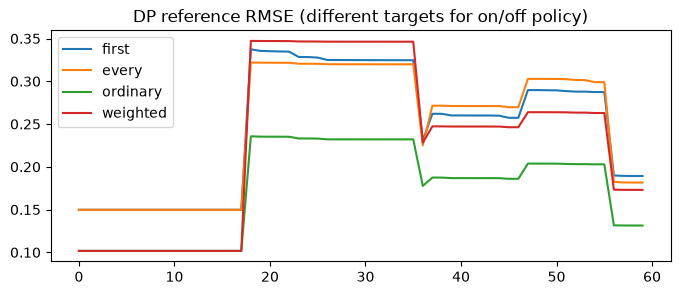

In [4]:
for episode_index in range(60 if FAST else 5000):
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    transitions = []
    total = 0.
    while True:
        selected = behavior.act(observation)
        log_b = selected.log_prob.detach().cpu().clone()  # 수집 시점의 확률
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약
        transitions.append(Transition(observation, selected.action, reward, next_observation, terminated, truncated, log_b))
        total += reward; observation = next_observation
        if terminated or truncated: break
    episode = Episode(transitions)
    if not episode.terminated: raise RuntimeError('MC에는 완료된 Episode가 필요합니다.')
    for name, learner in learners.items():
        learner.learn(episode)
        expected = reference if name in ('first','every') else off_reference
        rmse[name].append(float(np.sqrt(np.mean((models[name].estimator.v_table.numpy()[nonterminal]-expected[nonterminal])**2))))
    record(log, total, len(transitions), terminated, truncated)
for name in models:
    print(name, 'RMSE', round(rmse[name][-1], 6), 'V', np.round(models[name].estimator.v_table.numpy(), 4))
plt.figure(figsize=(8,3))
for name, curve in rmse.items(): plt.plot(curve, label=name)
plt.legend(); plt.title('DP reference RMSE (different targets for on/off policy)'); plt.show()

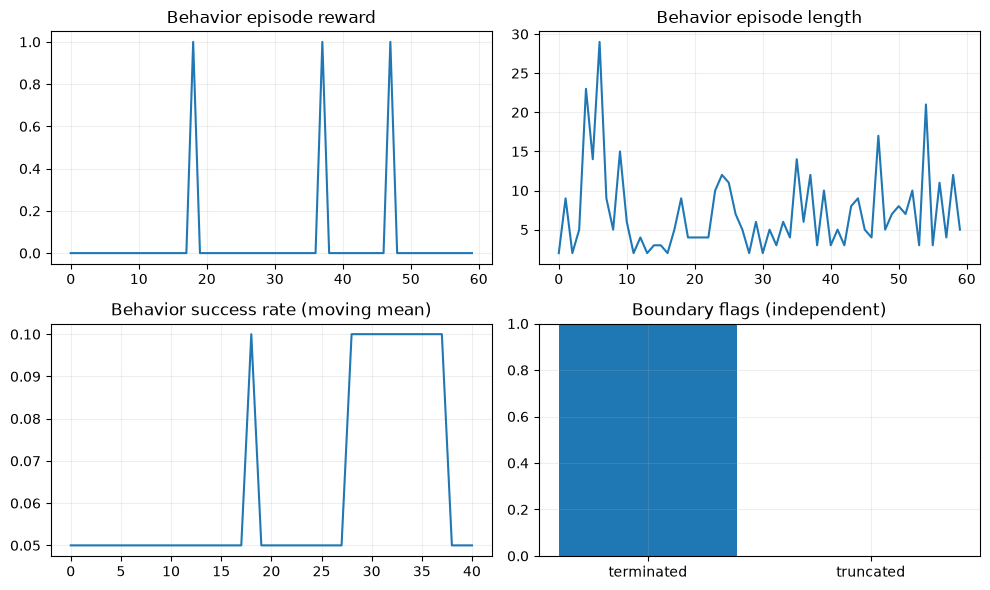

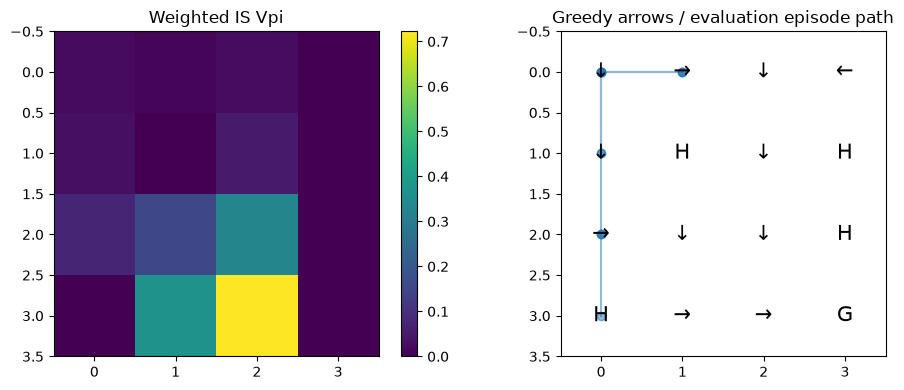

Weighted IS Vpi [0.022  0.0097 0.0246 0.     0.0302 0.     0.0521 0.     0.0735 0.1578
 0.3303 0.     0.     0.3675 0.7225 0.    ]
RESULT {"environment_steps": 433, "episodes": 60, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}
IS RMSE {'first': 0.189208, 'every': 0.181551, 'ordinary': 0.131321, 'weighted': 0.173007}


In [5]:
model = models['weighted']
# 지정 Target Policy 평가. 화살표는 추정 V에서 만든 Greedy 진단이며 수집 정책이 아니다.
table = model.estimator.v_table.numpy()
greedy = action_values(mdp, table, GAMMA).argmax(-1)
evaluation = evaluate(eval_env, lambda state: np_rng.choice(N_ACTIONS, p=target_policy[state].numpy()), episodes=20 if FAST else 200)
summary = frozen_report(desc, log, table, evaluation, greedy_actions=greedy, label='Weighted IS Vpi')
print('IS RMSE', {k: round(v[-1],6) for k,v in rmse.items()})
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
Episode 구성과 Behavior log_prob 보존이 명시적이다. ReturnGenerator를 고르고 sample average/IS 통계는 Learner가 맡는다. 재개 시 Model과 Learner count/weight 합을 함께 저장해야 한다. 선택 행동의 log b만으로 미관측 행동의 Coverage를 검증할 수 없다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.